In [1]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(X_train, _), _ = tf.keras.datasets.mnist.load_data()
X_train = np.expand_dims(X_train.astype("float32") / 127.5 - 1, -1)

latent_dim = 100
img_shape = X_train.shape[1:]

In [3]:
def build_generator():
    return tf.keras.Sequential([
        layers.Input((latent_dim,)),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dense(512, activation="relu"),
        layers.BatchNormalization(),
        layers.Dense(int(np.prod(img_shape)), activation="tanh"),
        layers.Reshape(img_shape)
    ])

def build_discriminator():
    return tf.keras.Sequential([
        layers.Input(img_shape),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

generator = build_generator()
discriminator = build_discriminator()

In [4]:
opt_d = tf.keras.optimizers.Adam(0.0002, 0.5)
opt_g = tf.keras.optimizers.Adam(0.0002, 0.5)

discriminator.compile(optimizer=opt_d, loss="binary_crossentropy", metrics=["accuracy"])
discriminator.trainable = False

gan_input = layers.Input((latent_dim,))
gan = tf.keras.Model(gan_input, discriminator(generator(gan_input)))
gan.compile(optimizer=opt_g, loss="binary_crossentropy")

In [5]:
def save_generated_images(epoch, examples=25):
    imgs = 0.5 * generator.predict(np.random.normal(0,1,(examples,latent_dim)), verbose=0) + 0.5
    plt.figure(figsize=(10,10))
    for i in range(examples):
        plt.subplot(5,5,i+1)
        plt.imshow(imgs[i,:,:,0], cmap="gray")
        plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"generated_{epoch}.png")
    plt.show()
    plt.close()

In [6]:
def train_gan(epochs=500, batch_size=64, save_interval=100):
    valid = np.ones((batch_size,1), dtype="float32")
    fake = np.zeros((batch_size,1), dtype="float32")

    for epoch in range(epochs):
        idx = np.random.randint(0, len(X_train), batch_size)
        real_imgs = X_train[idx]
        noise = np.random.normal(0,1,(batch_size,latent_dim))
        fake_imgs = generator.predict(noise, verbose=0)

        discriminator.trainable = True
        d_real = discriminator.train_on_batch(real_imgs, valid)
        d_fake = discriminator.train_on_batch(fake_imgs, fake)
        d_loss = 0.5 * (np.array(d_real) + np.array(d_fake))

        discriminator.trainable = False
        g_loss = gan.train_on_batch(np.random.normal(0,1,(batch_size,latent_dim)), valid)

        print(f"{epoch+1}/{epochs} [D loss: {d_loss[0]:.4f} | D acc: {100*d_loss[1]:.2f}%] [G loss: {float(np.asarray(g_loss)):.4f}]")

        if (epoch+1) % save_interval == 0:
            save_generated_images(epoch+1)

1/500 [D loss: 0.6625 | D acc: 48.44%] [G loss: 0.5908]
2/500 [D loss: 0.3694 | D acc: 95.31%] [G loss: 0.6249]
3/500 [D loss: 0.2976 | D acc: 100.00%] [G loss: 0.6313]
4/500 [D loss: 0.2508 | D acc: 100.00%] [G loss: 0.6920]
5/500 [D loss: 0.2052 | D acc: 100.00%] [G loss: 0.7472]
6/500 [D loss: 0.1765 | D acc: 100.00%] [G loss: 0.8132]
7/500 [D loss: 0.1579 | D acc: 100.00%] [G loss: 0.8762]
8/500 [D loss: 0.1239 | D acc: 100.00%] [G loss: 0.9004]
9/500 [D loss: 0.1149 | D acc: 100.00%] [G loss: 0.9838]
10/500 [D loss: 0.0949 | D acc: 100.00%] [G loss: 1.0811]
11/500 [D loss: 0.0878 | D acc: 100.00%] [G loss: 1.0627]
12/500 [D loss: 0.0728 | D acc: 100.00%] [G loss: 1.1224]
13/500 [D loss: 0.0787 | D acc: 100.00%] [G loss: 1.2099]
14/500 [D loss: 0.0700 | D acc: 100.00%] [G loss: 1.2292]
15/500 [D loss: 0.0722 | D acc: 100.00%] [G loss: 1.2768]
16/500 [D loss: 0.0672 | D acc: 100.00%] [G loss: 1.3582]
17/500 [D loss: 0.0684 | D acc: 100.00%] [G loss: 1.5080]
18/500 [D loss: 0.0648 | 

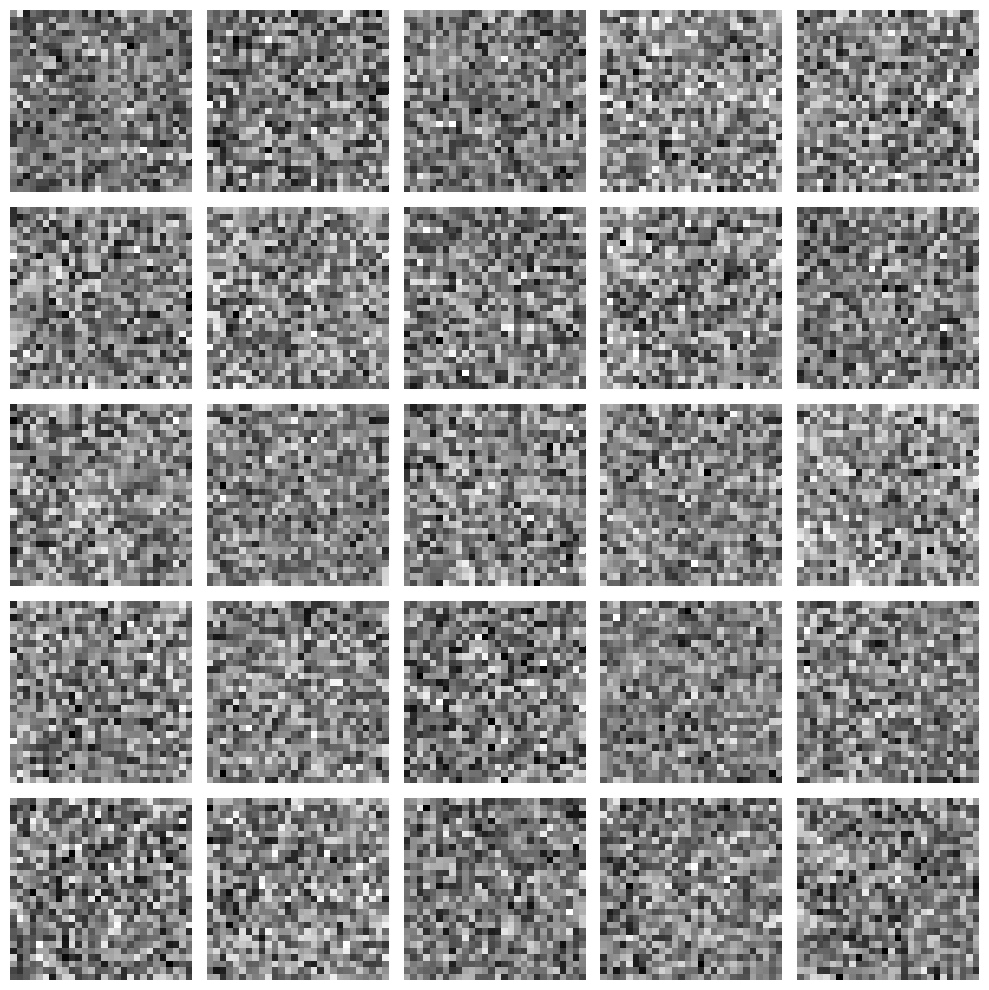

101/500 [D loss: 0.0057 | D acc: 100.00%] [G loss: 6.8488]
102/500 [D loss: 0.0071 | D acc: 100.00%] [G loss: 6.9214]
103/500 [D loss: 0.0072 | D acc: 100.00%] [G loss: 6.6271]
104/500 [D loss: 0.0086 | D acc: 100.00%] [G loss: 6.8220]
105/500 [D loss: 0.0091 | D acc: 100.00%] [G loss: 6.8503]
106/500 [D loss: 0.0122 | D acc: 100.00%] [G loss: 6.7620]
107/500 [D loss: 0.0088 | D acc: 100.00%] [G loss: 7.0592]
108/500 [D loss: 0.0107 | D acc: 100.00%] [G loss: 7.2295]
109/500 [D loss: 0.0102 | D acc: 100.00%] [G loss: 6.9069]
110/500 [D loss: 0.0093 | D acc: 100.00%] [G loss: 6.8510]
111/500 [D loss: 0.0083 | D acc: 100.00%] [G loss: 6.9499]
112/500 [D loss: 0.0079 | D acc: 100.00%] [G loss: 7.2464]
113/500 [D loss: 0.0125 | D acc: 100.00%] [G loss: 7.6065]
114/500 [D loss: 0.0084 | D acc: 100.00%] [G loss: 7.4029]
115/500 [D loss: 0.0062 | D acc: 100.00%] [G loss: 7.1965]
116/500 [D loss: 0.0087 | D acc: 100.00%] [G loss: 7.1881]
117/500 [D loss: 0.0075 | D acc: 100.00%] [G loss: 7.256

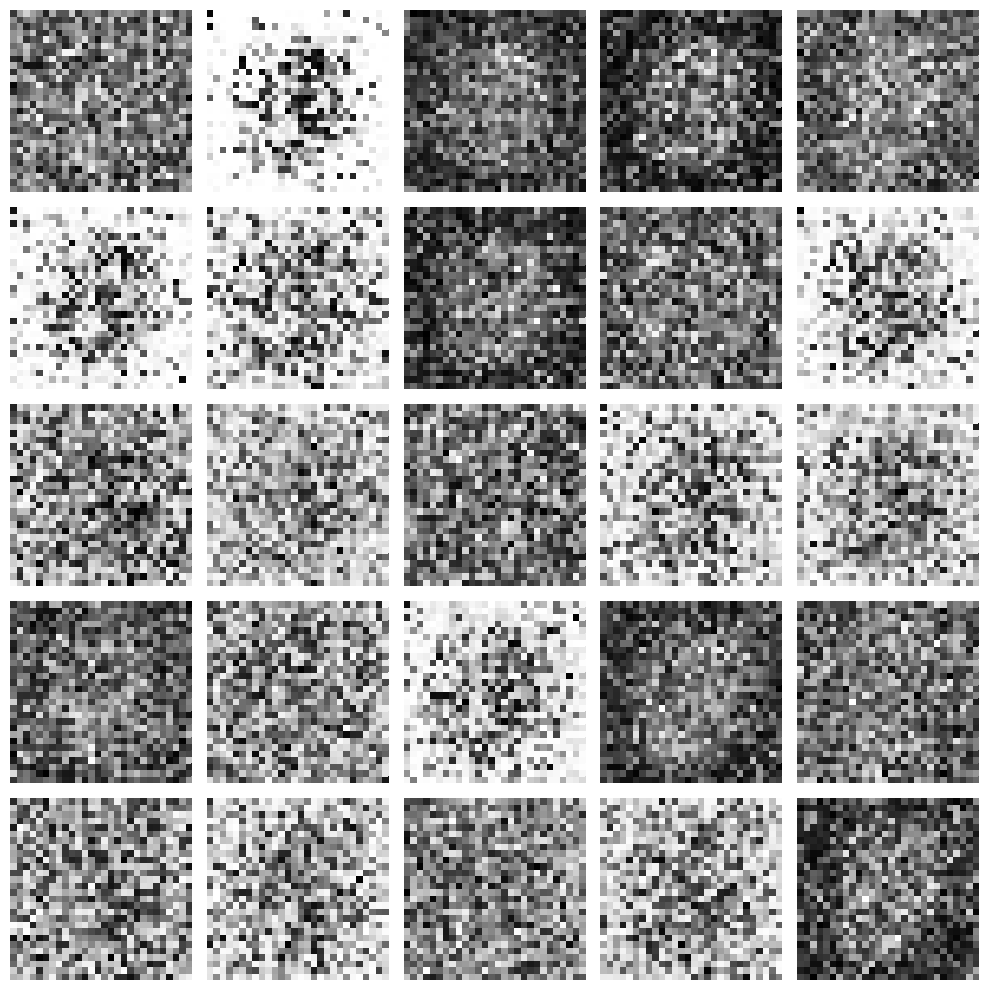

201/500 [D loss: 0.1852 | D acc: 89.84%] [G loss: 5.9144]
202/500 [D loss: 0.1879 | D acc: 91.41%] [G loss: 5.8857]
203/500 [D loss: 0.2261 | D acc: 88.28%] [G loss: 5.8235]
204/500 [D loss: 0.4239 | D acc: 77.34%] [G loss: 5.4866]
205/500 [D loss: 0.1786 | D acc: 92.97%] [G loss: 6.3197]
206/500 [D loss: 0.4277 | D acc: 79.69%] [G loss: 5.0791]
207/500 [D loss: 0.2107 | D acc: 88.28%] [G loss: 5.3903]
208/500 [D loss: 0.1051 | D acc: 97.66%] [G loss: 5.7372]
209/500 [D loss: 0.3770 | D acc: 82.03%] [G loss: 4.7553]
210/500 [D loss: 0.3019 | D acc: 82.03%] [G loss: 5.3903]
211/500 [D loss: 0.1480 | D acc: 96.09%] [G loss: 5.3655]
212/500 [D loss: 0.3835 | D acc: 81.25%] [G loss: 5.0157]
213/500 [D loss: 0.2227 | D acc: 86.72%] [G loss: 5.3219]
214/500 [D loss: 0.4262 | D acc: 78.12%] [G loss: 4.7399]
215/500 [D loss: 0.1859 | D acc: 92.97%] [G loss: 5.0419]
216/500 [D loss: 0.1852 | D acc: 89.84%] [G loss: 5.3651]
217/500 [D loss: 0.3946 | D acc: 77.34%] [G loss: 4.6330]
218/500 [D los

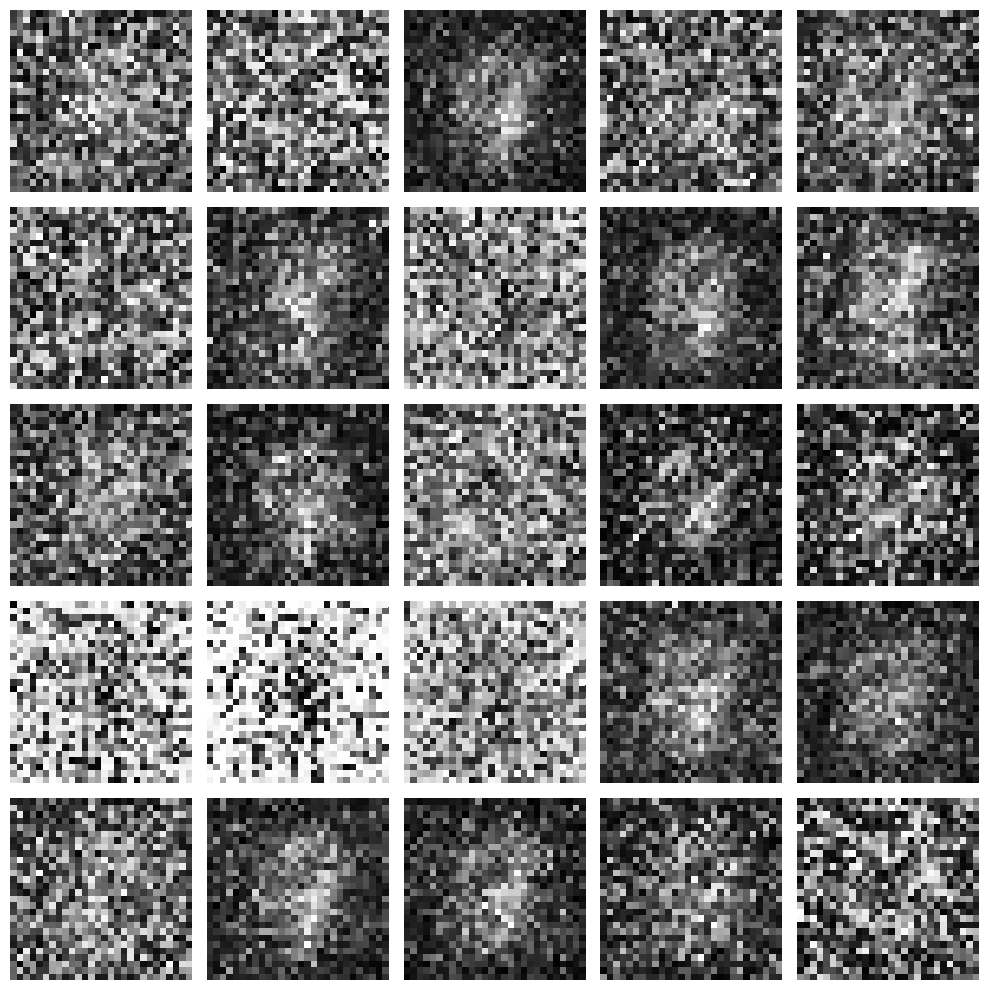

301/500 [D loss: 0.2624 | D acc: 92.19%] [G loss: 3.0553]
302/500 [D loss: 0.1381 | D acc: 96.88%] [G loss: 3.3029]
303/500 [D loss: 0.1715 | D acc: 96.09%] [G loss: 3.4609]
304/500 [D loss: 0.1875 | D acc: 93.75%] [G loss: 3.2732]
305/500 [D loss: 0.2172 | D acc: 94.53%] [G loss: 3.5310]
306/500 [D loss: 0.2242 | D acc: 89.06%] [G loss: 3.1313]
307/500 [D loss: 0.1494 | D acc: 97.66%] [G loss: 3.5926]
308/500 [D loss: 0.2741 | D acc: 86.72%] [G loss: 3.2366]
309/500 [D loss: 0.1557 | D acc: 95.31%] [G loss: 3.4815]
310/500 [D loss: 0.2928 | D acc: 85.94%] [G loss: 3.3082]
311/500 [D loss: 0.1552 | D acc: 97.66%] [G loss: 3.5453]
312/500 [D loss: 0.2030 | D acc: 94.53%] [G loss: 2.7296]
313/500 [D loss: 0.2035 | D acc: 95.31%] [G loss: 3.3904]
314/500 [D loss: 0.2731 | D acc: 86.72%] [G loss: 3.6936]
315/500 [D loss: 0.2920 | D acc: 84.38%] [G loss: 3.2758]
316/500 [D loss: 0.1956 | D acc: 95.31%] [G loss: 3.7198]
317/500 [D loss: 0.3565 | D acc: 78.91%] [G loss: 3.5738]
318/500 [D los

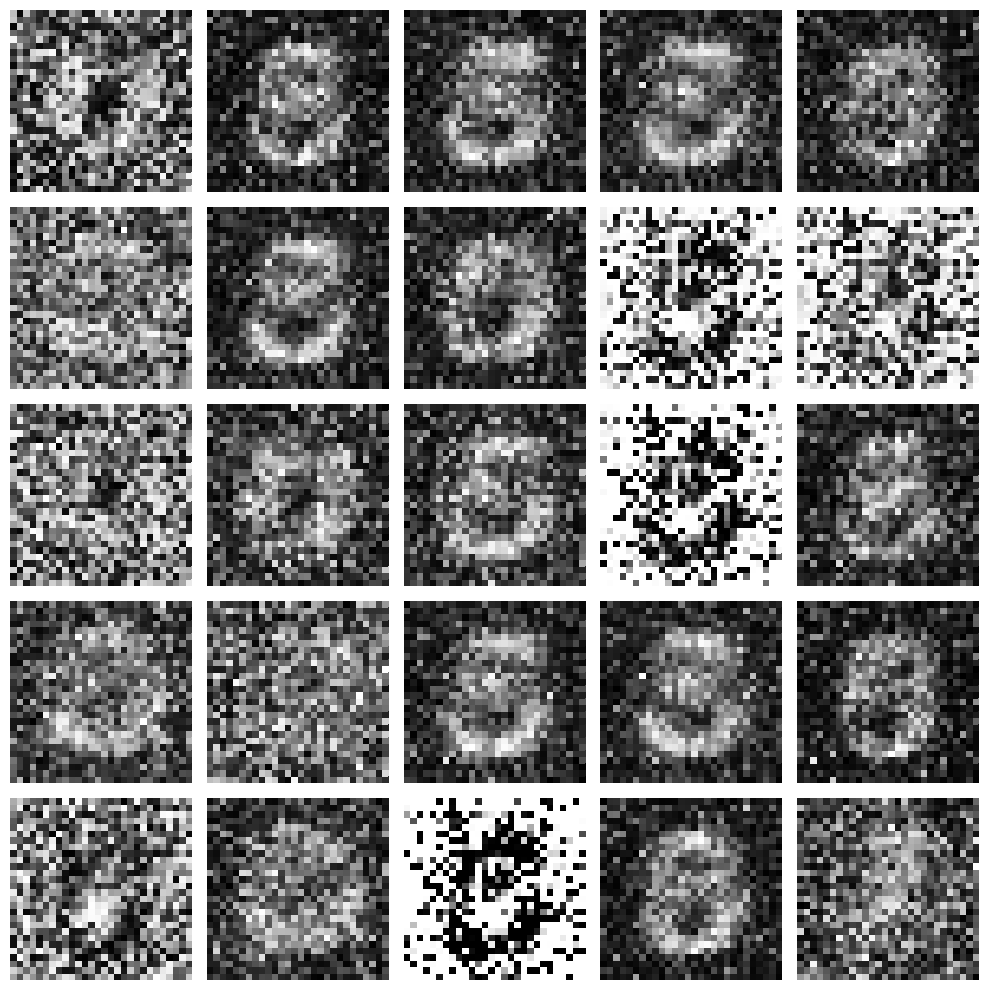

401/500 [D loss: 0.1828 | D acc: 94.53%] [G loss: 4.2227]
402/500 [D loss: 0.2563 | D acc: 91.41%] [G loss: 3.8265]
403/500 [D loss: 0.2276 | D acc: 91.41%] [G loss: 3.9585]
404/500 [D loss: 0.2558 | D acc: 89.06%] [G loss: 4.4491]
405/500 [D loss: 0.3408 | D acc: 85.94%] [G loss: 4.3718]
406/500 [D loss: 0.2235 | D acc: 93.75%] [G loss: 3.9291]
407/500 [D loss: 0.3314 | D acc: 84.38%] [G loss: 3.8893]
408/500 [D loss: 0.3123 | D acc: 89.06%] [G loss: 3.8660]
409/500 [D loss: 0.2884 | D acc: 85.94%] [G loss: 3.9182]
410/500 [D loss: 0.4164 | D acc: 75.78%] [G loss: 3.2403]
411/500 [D loss: 0.1587 | D acc: 95.31%] [G loss: 4.4718]
412/500 [D loss: 0.5513 | D acc: 70.31%] [G loss: 3.5950]
413/500 [D loss: 0.1297 | D acc: 97.66%] [G loss: 4.1031]
414/500 [D loss: 0.2102 | D acc: 94.53%] [G loss: 3.7729]
415/500 [D loss: 0.3482 | D acc: 82.03%] [G loss: 3.8651]
416/500 [D loss: 0.2082 | D acc: 94.53%] [G loss: 4.2787]
417/500 [D loss: 0.3189 | D acc: 87.50%] [G loss: 3.2840]
418/500 [D los

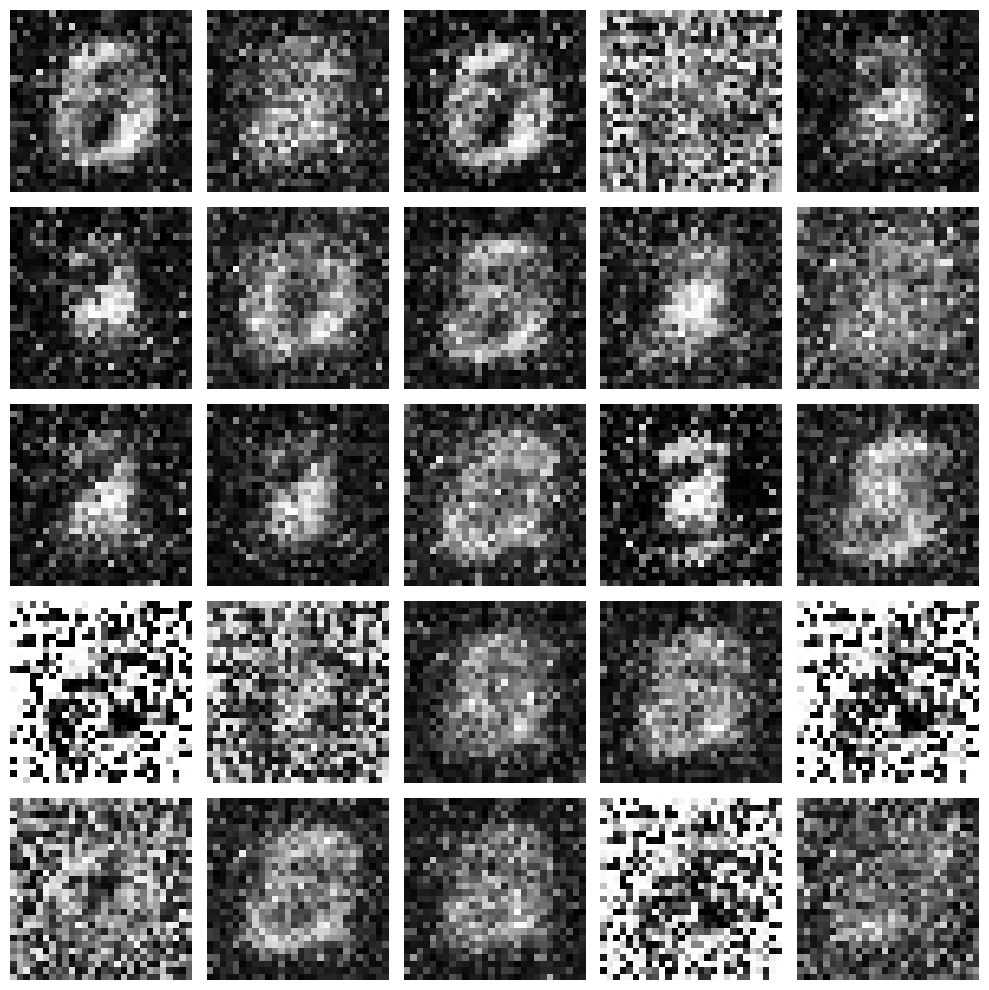

In [7]:
train_gan()